# 11. Nonlinear waves: solitons, shocks and chaos

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ktwyw/spectral-methods-in-python/blob/main/notebooks/11_nonlinear_waves.ipynb)

*Companion to Chapter 10 of L. N. Trefethen, Spectral Methods in MATLAB (SIAM, 2000).*

Three famous nonlinear equations share the same nonlinear term, $u\,u_x$, and differ only in
their linear part. Dispersion gives the Korteweg-de Vries equation and its solitons. Diffusion
gives the Burgers equation and its shocks. An unstable mix of second and fourth derivatives
gives the Kuramoto-Sivashinsky equation and chaos. On a periodic domain each of them takes
about twenty lines of Fourier spectral code, and each can be checked against exact results.

- Fourier methods on a domain of any period $L$
- stiff linear terms removed exactly: the **integrating factor** and **exponential time differencing**
- solitons that pass through each other, and the phase shift they pick up
- a viscous shock, an exact solution to test it, and how a Fourier spectrum warns of too few points
- spatio-temporal chaos from a smooth start

**Worked examples:** a soliton collision (shallow-water waves), a steepening viscous shock
(gas dynamics), and the chaotic cells of a falling liquid film.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from numpy.fft import rfft, irfft
from matplotlib.animation import FuncAnimation, PillowWriter

plt.rcParams.update({
    "axes.prop_cycle": plt.cycler(color=["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]),
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.3, "lines.linewidth": 2, "figure.figsize": (6.4, 4),
})

## 11.1 One nonlinear term, three linear parts

All three equations of this notebook have the form

$$u_t = \mathcal{L}u - u\,u_x ,$$

where $\mathcal{L}$ is a linear operator with constant coefficients. A Fourier mode $e^{ikx}$
is an eigenfunction of such an operator, $\mathcal{L}e^{ikx} = \ell(k)\,e^{ikx}$, and the number
$\ell(k)$ is called the **symbol**:

| Equation | $\mathcal{L}u$ | symbol $\ell(k)$ | effect on mode $k$ |
| --- | --- | --- | --- |
| Korteweg-de Vries | $-u_{xxx}$ | $ik^3$ | travels, speed depends on $k$ (dispersion) |
| Burgers | $\nu u_{xx}$ | $-\nu k^2$ | decays (diffusion) |
| Kuramoto-Sivashinsky | $-u_{xx} - u_{xxxx}$ | $k^2 - k^4$ | grows for $|k| < 1$, decays for $|k| > 1$ |

**A domain of period $L$.** The Fourier grid of notebook 2 has period $2\pi$ and integer
wavenumbers. For a period $L$, stretch the coordinate: $x = Ls/(2\pi)$ with $s$ on the standard
grid. By the chain rule $d/dx = (2\pi/L)\,d/ds$, so mode number $n$ has the wavenumber
$k = 2\pi n/L$, and nothing else changes.

**Real data.** The solutions here are real, so the coefficients of $-k$ are the complex
conjugates of those of $+k$ and need not be stored. `rfft` keeps only $n = 0, \dots, N/2$ and
`irfft` returns a real array. This halves the work, and it has a second benefit that matters
in 11.6: rounding errors cannot create an imaginary part of $u$.

**The nonlinear term** is computed on the grid: transform to grid values, multiply there,
transform back, and differentiate in Fourier space. A method that takes derivatives in Fourier
space and products on the grid is called **pseudo-spectral**. Writing $u\,u_x = (u^2/2)_x$
needs only one transform pair. The last stored mode is the Nyquist mode, which is set to zero
in an odd derivative (notebook 2).

The product has a price. If $u$ holds wavenumbers up to $k_{\max}$, then $u^2$ holds
wavenumbers up to $2k_{\max}$, and the grid folds those above $k_{\max}$ back onto lower ones:
the aliasing of notebook 2. The error is negligible as long as the upper half of the spectrum
is nearly empty, which holds for every resolved solution in this notebook. Notebooks 15 and 16
show what happens otherwise and how to remove the error.

In [2]:
def wavenumbers(N, L):
    """Wavenumbers k = 2πn/L, n = 0..N/2, of real data with period L on N points (for rfft)."""
    return 2 * np.pi * np.fft.rfftfreq(N, d=L / N)

def advection_term(k):
    """Function that maps the rfft of u to the rfft of -u u_x = -(u²/2)_x."""
    N = 2 * (len(k) - 1)
    ik = 1j * k
    ik[-1] = 0                                             # Nyquist mode: no odd derivative
    return lambda u_hat: -0.5 * ik * rfft(irfft(u_hat, N) ** 2)

# check on u = sin(2πx/L): -u u_x = -(π/L) sin(4πx/L)
N, L = 32, 5.0
x = L * np.arange(N) / N
test = irfft(advection_term(wavenumbers(N, L))(rfft(np.sin(2 * np.pi * x / L))), N)
assert np.abs(test + np.pi / L * np.sin(4 * np.pi * x / L)).max() < 1e-12

## 11.2 Stiffness and the integrating factor

In Fourier space the equation is a system of ordinary differential equations, one per mode:

$$\hat u_t = \ell(k)\,\hat u + \hat{\mathcal N}(\hat u), \qquad \hat{\mathcal N} = \text{transform of } -u\,u_x .$$

Notebook 9 showed the difficulty. An explicit formula is stable only if $\Delta t\,\ell(k)$
lies in its stability region for **every** $k$ on the grid, and $|\ell|$ reaches
$k_{\max}^3$ or $k_{\max}^4$ with $k_{\max} = \pi N/L$. The problem is **stiff**: the step is
dictated by the highest modes, which carry almost no energy.

**By hand.** The stiff term is linear and diagonal, so it can be integrated exactly. Define

$$\hat v(t) = e^{-\ell t}\,\hat u(t)
\quad\Longrightarrow\quad
\hat v_t = e^{-\ell t}\big(\hat u_t - \ell\hat u\big) = e^{-\ell t}\,\hat{\mathcal N}\big(e^{\ell t}\hat v\big).$$

The linear term has disappeared. This is the same **integrating factor** used to solve a
first-order linear ODE by hand. Classical RK4 is now applied to $\hat v$. Restarting the
factor at the beginning of each step, so that $\hat v = \hat u$ there, and writing
$E = e^{\ell\Delta t/2}$, one step reads

$$a = \Delta t\,\hat{\mathcal N}(\hat u),\quad
b = \Delta t\,\hat{\mathcal N}\big(E(\hat u + \tfrac a2)\big),\quad
c = \Delta t\,\hat{\mathcal N}\big(E\hat u + \tfrac b2\big),\quad
d = \Delta t\,\hat{\mathcal N}\big(E^2\hat u + Ec\big),$$

$$\hat u_{\text{new}} = E^2\hat u + \tfrac16\big(E^2 a + 2E(b + c) + d\big).$$

With $\hat{\mathcal N} = 0$ this is $\hat u_{\text{new}} = e^{\ell\Delta t}\hat u$, the exact
solution of the linear problem for any step size.

In [3]:
def ifrk4(u_hat, symbol, nonlinear, dt, steps):
    """Advance u_hat' = symbol * u_hat + nonlinear(u_hat) by `steps` steps of integrating-factor RK4."""
    E = np.exp(symbol * dt / 2)
    E2 = E * E
    for _ in range(steps):
        a = dt * nonlinear(u_hat)
        b = dt * nonlinear(E * (u_hat + a / 2))
        c = dt * nonlinear(E * u_hat + b / 2)
        d = dt * nonlinear(E2 * u_hat + E * c)
        u_hat = E2 * u_hat + (E2 * a + 2 * E * (b + c) + d) / 6
    return u_hat

## 11.3 Korteweg-de Vries: one soliton

**Problem.** The Korteweg-de Vries (KdV) equation

$$u_t + u\,u_x + u_{xxx} = 0$$

describes long waves of small amplitude on shallow water. Nonlinearity steepens a hump and
dispersion spreads it. When the two balance exactly the hump travels without change of shape,
a **solitary wave**:

$$u(x, t) = 3c\,\operatorname{sech}^2\!\Big(\tfrac{\sqrt c}{2}\,(x - ct - x_0)\Big).$$

Its speed $c$, its height $3c$ and its width $2/\sqrt c$ are tied together: tall waves are
narrow and fast. Substituting into the equation confirms it (a good exercise by hand, using
$\operatorname{sech}'' = \operatorname{sech} - 2\operatorname{sech}^3$).

Send a soliton of speed $c = 16$ across a periodic domain of length 30 and compare with the
exact profile.

In [4]:
N, L = 256, 30.0
x = -L / 2 + L * np.arange(N) / N
k = wavenumbers(N, L)
kdv_symbol = 1j * k**3
kdv_symbol[-1] = 0                                         # odd derivative: drop the Nyquist mode
kdv_nonlinear = advection_term(k)

def soliton(x, t, c, x0, L=30.0):
    """KdV solitary wave of speed c that starts at x0, wrapped onto the periodic domain of length L."""
    distance = (x - c * t - x0 + L / 2) % L - L / 2
    return 3 * c / np.cosh(np.sqrt(c) / 2 * distance) ** 2

k_max, u_max = k[-1], 48.0
print(f"largest |symbol| = k_max³ = {k_max**3:.0f}:  plain RK4 would need dt < {2.83 / k_max**3:.1e}")
print(f"with the integrating factor only the nonlinear term limits the step: dt < about {2.83 / (k_max * u_max):.1e}")

largest |symbol| = k_max³ = 19267:  plain RK4 would need dt < 1.5e-04
with the integrating factor only the nonlinear term limits the step: dt < about 2.2e-03


The second limit comes from the nonlinear term, which acts like advection at speed $u$ and so
puts $\Delta t\,k_{\max}|u|$ on the imaginary axis, where RK4 reaches 2.83 (notebook 9). The
stability limit is 15 times larger here, and the factor grows like $N^2$.

Stability is not accuracy, though. The integrating factor has large error constants when
$|\ell|\Delta t$ is large (11.6 returns to this). For this tall, narrow soliton a step of
$10^{-3}$, seven times the limit of plain RK4, is stable but gives only three digits, and an
error of $10^{-7}$ needs $\Delta t = 5\times10^{-5}$, below even the plain limit. The larger
steps pay off when modest accuracy is enough and for wider, slower waves, as in test (b).

**Verify** (a) against the exact solution after the soliton has travelled 8 units, (b) the order
of convergence in $\Delta t$, and (c) two conservation laws. Integrating the equation over one
period shows that the **mass** $\int u\,dx$ is constant; multiplying by $u$ first shows the same
for the **momentum** $\int u^2\,dx$. On a periodic grid both integrals are plain sums times
$h = L/N$, with spectral accuracy (notebook 10).

In [5]:
c_test, x_start, t_end = 16.0, -8.0, 0.5
u_start = soliton(x, 0, c_test, x_start)
exact = soliton(x, t_end, c_test, x_start)

u_end = irfft(ifrk4(rfft(u_start), kdv_symbol, kdv_nonlinear, 5e-5, 10_000), N)
error = np.abs(u_end - exact).max()
print(f"(a) dt = 5e-05: largest error after travelling {c_test * t_end:.0f} units = {error:.1e}   (wave height 48)")
assert error < 1e-6
coarse = irfft(ifrk4(rfft(u_start), kdv_symbol, kdv_nonlinear, 1e-3, 500), N)
coarse_error = np.abs(coarse - exact).max()
print(f"    dt = 1e-03: largest error = {coarse_error:.1e}, that is {coarse_error / 48:.1e} of the wave height: stable, far less accurate")
assert 1e-3 < coarse_error < 0.1

errors = {}
for steps in (500, 1000, 2000, 4000):                       # (b) a gentler soliton, c = 4, four step sizes
    dt = 1.0 / steps
    result = irfft(ifrk4(rfft(soliton(x, 0, 4.0, x_start)), kdv_symbol, kdv_nonlinear, dt, steps), N)
    errors[dt] = np.abs(result - soliton(x, 1.0, 4.0, x_start)).max()
e = np.array(list(errors.values()))
orders = np.log2(e[:-1] / e[1:])
print("(b) c = 4, errors at t = 1:", "  ".join(f"dt = {dt:.2e}: {err:.1e}" for dt, err in errors.items()))
print("    observed orders", np.round(orders, 2))
assert np.all(np.abs(orders - 4) < 0.2)

h = L / N
mass_drift = abs(u_end.sum() - u_start.sum()) * h / (u_start.sum() * h)
momentum_drift = abs((u_end**2).sum() - (u_start**2).sum()) / (u_start**2).sum()
print(f"(c) relative change of mass {mass_drift:.1e}, of momentum {momentum_drift:.1e}")
assert mass_drift < 1e-12 and momentum_drift < 1e-9

(a) dt = 5e-05: largest error after travelling 8 units = 1.7e-07   (wave height 48)
    dt = 1e-03: largest error = 5.9e-02, that is 1.2e-03 of the wave height: stable, far less accurate


(b) c = 4, errors at t = 1: dt = 2.00e-03: 4.2e-06  dt = 1.00e-03: 2.4e-07  dt = 5.00e-04: 1.5e-08  dt = 2.50e-04: 8.9e-10
    observed orders [4.12 4.05 4.03]
(c) relative change of mass 1.4e-16, of momentum 1.1e-10


The profile is right to eight digits of the wave height. The remaining $10^{-7}$ is the
spatial error of this grid for so narrow a wave, so the order test (b) uses a wider soliton,
for which the spatial error is negligible and the time-stepping error is seen alone: it falls
by a factor of 16 for each halving of $\Delta t$. Mass is conserved to rounding
because the nonlinear term has no $k = 0$ component; momentum is conserved to the accuracy of
the time stepping.

## 11.4 Two solitons collide

**Problem.** Put a tall soliton ($c_1 = 16$) behind a short one ($c_2 = 4$). The tall one
catches up. The equation is nonlinear, so two solutions cannot be added to give a third, and there is no
reason to expect either to survive the collision.

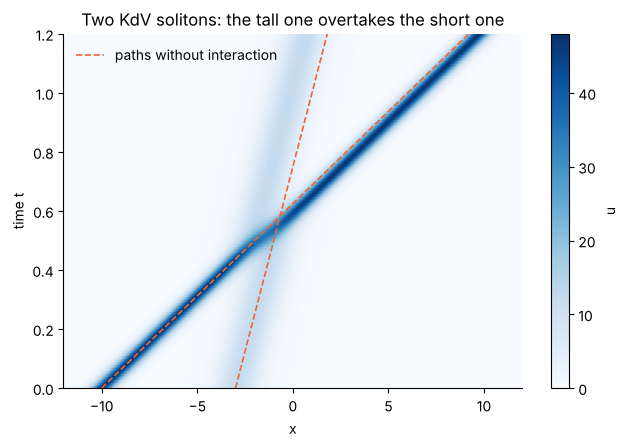

In [6]:
c1, x1, c2, x2 = 16.0, -10.0, 4.0, -3.0
u0 = soliton(x, 0, c1, x1) + soliton(x, 0, c2, x2)

dt, steps_per_frame, frames = 2e-4, 50, 120
u_hat = rfft(u0)
history = [u0]
for _ in range(frames):
    u_hat = ifrk4(u_hat, kdv_symbol, kdv_nonlinear, dt, steps_per_frame)
    history.append(irfft(u_hat, N))
history = np.array(history)
times = dt * steps_per_frame * np.arange(frames + 1)

fig, ax = plt.subplots(figsize=(7.4, 4.6))
mesh = ax.pcolormesh(x, times, history, cmap="Blues", shading="gouraud", rasterized=True)
for c, x0, label in ((c1, x1, "paths without interaction"), (c2, x2, None)):
    ax.plot(x0 + c * times, times, "--", color="#eb6834", lw=1.2, label=label)
ax.set(xlim=(-12, 12), ylim=(0, times[-1]), xlabel="x", ylabel="time t",
       title="Two KdV solitons: the tall one overtakes the short one")
ax.grid(False)
ax.legend(frameon=False, loc="upper left")
fig.colorbar(mesh, label="u");

Both waves come out of the collision intact. The only trace of the encounter is a **phase
shift**: the tall soliton emerges ahead of the dashed line it would have followed alone, and
the short one behind its line. During the overlap the peak is *lower* than the tall soliton
alone, another sign that this is not a superposition.

**By hand.** The exact two-soliton solution (found in the 1960s and 70s by the inverse
scattering and Hirota methods) gives the shifts in closed form. With
$\kappa_i = \sqrt{c_i}/2$,

$$\Delta x_{\text{tall}} = +\frac{1}{\kappa_1}\ln\frac{\kappa_1 + \kappa_2}{\kappa_1 - \kappa_2},\qquad
\Delta x_{\text{short}} = -\frac{1}{\kappa_2}\ln\frac{\kappa_1 + \kappa_2}{\kappa_1 - \kappa_2}.$$

For $c_1 = 16$, $c_2 = 4$: $\kappa_1 = 2$, $\kappa_2 = 1$, so the shifts are
$+\tfrac12\ln 3 = 0.5493$ and $-\ln 3 = -1.0986$.

**Verify.** Locate the two peaks at the final time. The grid spacing is 0.12, too coarse to read
a position from directly, so the helper below evaluates the trigonometric interpolant on a grid
16 times finer (`fourier_interpolate`, the zero padding of notebook 2) and then fits a parabola
through the three values around each maximum.

In [7]:
# fourier_interpolate(v, M) from notebook 2
def fourier_interpolate(v, M):
    """Values of the trigonometric interpolant of v (N samples, N even) on the periodic grid of M > N points."""
    N = len(v)
    v_hat = np.fft.fft(v)
    padded = np.zeros(M, dtype=complex)
    padded[: N // 2] = v_hat[: N // 2]                         # k = 0, ..., N/2 - 1
    padded[M - N // 2 + 1 :] = v_hat[N // 2 + 1 :]             # k = -N/2 + 1, ..., -1
    padded[N // 2] = padded[M - N // 2] = v_hat[N // 2] / 2    # the Nyquist mode, shared between ±N/2
    return np.real(np.fft.ifft(padded)) * M / N

def peaks(u, L, refine=16):
    """Positions and heights of the local maxima of periodic data, highest first."""
    M = refine * len(u)
    fine = fourier_interpolate(u, M)                        # the trigonometric interpolant on M points
    xf = -L / 2 + L * np.arange(M) / M
    j = np.flatnonzero((fine > np.roll(fine, 1)) & (fine >= np.roll(fine, -1)) & (fine > 0.1 * fine.max()))
    left, mid, right = fine[j - 1], fine[j], fine[(j + 1) % M]
    shift = 0.5 * (left - right) / (left - 2 * mid + right)  # vertex of the parabola, in grid units
    order = np.argsort(-mid)
    return (xf[j] + shift * L / M)[order], (mid - 0.25 * (left - right) * shift)[order]

positions, heights = peaks(history[-1], L)
T = times[-1]
shift_tall, shift_short = positions[0] - (x1 + c1 * T), positions[1] - (x2 + c2 * T)
print(f"heights after the collision: {heights[0]:.4f} and {heights[1]:.4f}    (before: 48 and 12)")
print(f"phase shift of the tall soliton  {shift_tall:+.4f}   theory {np.log(3) / 2:+.4f}")
print(f"phase shift of the short soliton {shift_short:+.4f}   theory {-np.log(3):+.4f}")
assert len(positions) == 2 and np.allclose(heights, [3 * c1, 3 * c2], rtol=1e-4)
assert abs(shift_tall - np.log(3) / 2) < 1e-3 and abs(shift_short + np.log(3)) < 1e-3

# the speeds after the collision, from the peak positions in the last 0.2 time units
late = times >= T - 0.2
tracks = np.array([peaks(u, L)[0] for u in history[late]])
speeds = np.polyfit(times[late], tracks, 1)[0]
print(f"speeds after the collision: {speeds[0]:.3f} and {speeds[1]:.3f}")
assert np.allclose(speeds, [c1, c2], rtol=2e-3)
h = L / N
assert abs(history[-1].sum() - u0.sum()) * h < 1e-10 and abs((history[-1] ** 2).sum() / (u0**2).sum() - 1) < 1e-6

heights after the collision: 48.0001 and 12.0000    (before: 48 and 12)
phase shift of the tall soliton  +0.5494   theory +0.5493
phase shift of the short soliton -1.0986   theory -1.0986
speeds after the collision: 16.000 and 4.000


Heights, speeds and both phase shifts agree with the theory. Solitary waves that survive
collisions like particles were named **solitons** for this reason.

The next cell writes the animation to `kdv_solitons.gif` next to the notebook. The copy shown
below it is the one stored in the repository.

In [8]:
fig, ax = plt.subplots(figsize=(6, 2.6), dpi=80)
line, = ax.plot(x, history[0], color="#2a78d6")
ax.set(xlim=(-12, 12), ylim=(-2, 60), xlabel="x", ylabel="u", title="Two solitons of the KdV equation")
label = ax.text(0.5, 0.96, "", transform=ax.transAxes, ha="center", va="top")
fig.tight_layout()

def draw(frame):
    line.set_ydata(history[frame])
    label.set_text(f"t = {times[frame]:.2f}")
    return line, label

FuncAnimation(fig, draw, frames=len(history), blit=True).save("kdv_solitons.gif", writer=PillowWriter(fps=20), dpi=80)
plt.close(fig)

![Two KdV solitons: the tall, fast one overtakes the short one](https://raw.githubusercontent.com/ktwyw/spectral-methods-in-python/main/notebooks/kdv_solitons.gif)

**What it means.** A soliton keeps its shape over very long distances. That is why a hump of
water can run for kilometres along a shallow canal, why KdV-type models are used for the
propagation of tsunami and internal waves in the ocean, and why pulses of the right shape can
carry data along thousands of kilometres of optical fibre without spreading (there the
governing equation is the nonlinear Schrödinger equation of exercise 3, and the balance
between nonlinearity and dispersion is the same). For the
numerical analyst the soliton is a severe test: any error in the balance between $u\,u_x$ and
$u_{xxx}$ shows up as a wrong speed or as ripples shed behind the wave.

## 11.5 Burgers: a viscous shock

**Problem.** Replace dispersion by diffusion:

$$u_t + u\,u_x = \nu\,u_{xx},\qquad u(x, 0) = \sin x \quad\text{on } [0, 2\pi).$$

This is the simplest model of a compressible flow. Each part of the profile moves at its own
speed $u$, so the wave leans forward where $u_x < 0$ and steepens, here at $x = \pi$. Without
viscosity the slope becomes infinite at $t = 1$. With viscosity the steepening stops when
diffusion across the front balances it, and a **shock** of finite thickness forms.

**By hand: an exact solution.** The Cole-Hopf transformation $u = -2\nu\,\varphi_x/\varphi$
turns the Burgers equation into the heat equation $\varphi_t = \nu\varphi_{xx}$ (substitute and
check). The initial condition $u = \sin x$ corresponds to
$\varphi(x, 0) = \exp\!\big(\cos x/(2\nu)\big)$, and the heat equation damps each Fourier
coefficient of $\varphi$ by $e^{-\nu k^2 t}$. So the exact solution at any time costs two
transforms.

ν = 0.1, N = 128, t = 1: largest error against Cole-Hopf = 5.1e-10
ν = 0.1, N = 128, t = 2: largest error against Cole-Hopf = 1.3e-09


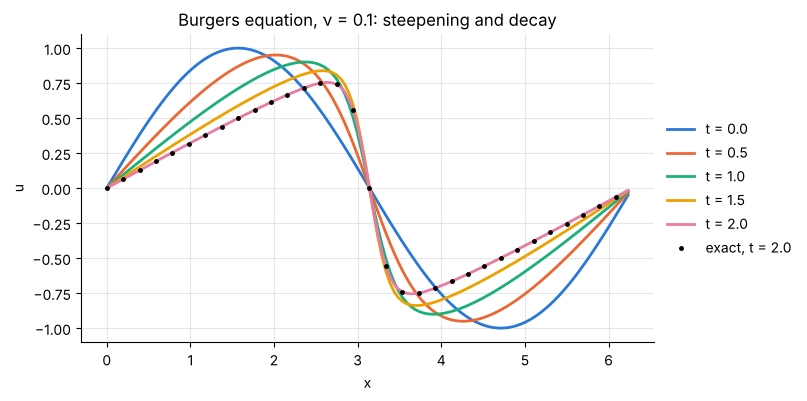

In [9]:
def cole_hopf(N, t, nu, N_ref=1024):
    """Exact Burgers solution for u(x, 0) = sin x on the N-point grid (N must divide N_ref)."""
    xr = 2 * np.pi * np.arange(N_ref) / N_ref
    kr = wavenumbers(N_ref, 2 * np.pi)
    phi_hat = rfft(np.exp(np.cos(xr) / (2 * nu))) * np.exp(-nu * kr**2 * t)
    ikr = 1j * kr
    ikr[-1] = 0
    u = -2 * nu * irfft(ikr * phi_hat, N_ref) / irfft(phi_hat, N_ref)
    return u[:: N_ref // N]

def burgers(N, nu, t_end, dt):
    """Pseudo-spectral Burgers solution from u = sin x: integrating factor for the viscous term."""
    x = 2 * np.pi * np.arange(N) / N
    k = wavenumbers(N, 2 * np.pi)
    u_hat = ifrk4(rfft(np.sin(x)), -nu * k**2, advection_term(k), dt, round(t_end / dt))
    return x, irfft(u_hat, N)

nu = 0.1
fig, ax = plt.subplots(figsize=(7.4, 4))
for t in (0.0, 0.5, 1.0, 1.5, 2.0):
    xg, u = burgers(128, nu, t, 0.005)
    error = np.abs(u - cole_hopf(128, t, nu)).max()
    ax.plot(xg, u, label=f"t = {t:.1f}")
    if t in (1.0, 2.0):
        print(f"ν = {nu}, N = 128, t = {t:.0f}: largest error against Cole-Hopf = {error:.1e}")
        assert error < 1e-8
ax.plot(xg[::4], cole_hopf(128, 2.0, nu)[::4], "k.", ms=5, label="exact, t = 2.0")
ax.set(xlabel="x", ylabel="u", title="Burgers equation, ν = 0.1: steepening and decay")
ax.legend(frameon=False, loc="center left", bbox_to_anchor=(1.0, 0.5));

With $\nu = 0.1$ the front is gentle and 128 points give nine digits.

**A thinner shock.** Lower the viscosity to $\nu = 0.01$. The reference needs care first: now
$\varphi(x, 0)$ ranges over $e^{100} \approx 10^{43}$, far more than the sixteen digits of
floating point, and the Fourier form above loses all accuracy near $x = \pi$, exactly where the
shock sits. The same exact solution in a form without cancellation uses the heat kernel:

$$u(x, t) = \frac{\displaystyle\int_{-\infty}^{\infty} \frac{s}{t}\; w(x, s)\,ds}{\displaystyle\int_{-\infty}^{\infty} w(x, s)\,ds},
\qquad w(x, s) = \exp\!\Big(-\frac{s^2}{4\nu t} + \frac{\cos(x - s)}{2\nu}\Big).$$

All the weights are positive, so nothing cancels, and the trapezoidal rule on a fine grid in
$s$ converges geometrically (notebook 10).

In [10]:
def cole_hopf_kernel(x, t, nu, n=4001):
    """Exact Burgers solution for u(x, 0) = sin x from the heat-kernel form; safe for small ν."""
    s = np.linspace(-3 * np.pi, 3 * np.pi, n)
    exponent = -s**2 / (4 * nu * t) + np.cos(x[:, None] - s) / (2 * nu)
    w = np.exp(exponent - exponent.max(axis=1, keepdims=True))        # scaled to avoid overflow
    return (w * s).sum(axis=1) / w.sum(axis=1) / t

xg = 2 * np.pi * np.arange(128) / 128
difference = np.abs(cole_hopf_kernel(xg, 2.0, 0.1) - cole_hopf(128, 2.0, 0.1)).max()
print(f"the two forms of the exact solution agree to {difference:.1e} at ν = 0.1")
assert difference < 1e-11

the two forms of the exact solution agree to 8.7e-14 at ν = 0.1


Now run the pseudo-spectral code with $N = 64$, half the number used for $\nu = 0.1$, and look
at both the solution and the size of its Fourier coefficients.

N = 64      t    largest error   spectrum tail
          0.5      2.9e-09      1.0e-08
          0.8      3.6e-04      3.0e-04
          1.0      2.4e-02      1.5e-02
          1.5      3.1e-01      3.4e-01


N = 1024   1.5      1.9e-07      7.8e-09


largest u at t = 1 with N = 64: 1.0005
steepest slope at t = 1.5: 47.8    estimate U²/(2ν) with U = max u: 48.5


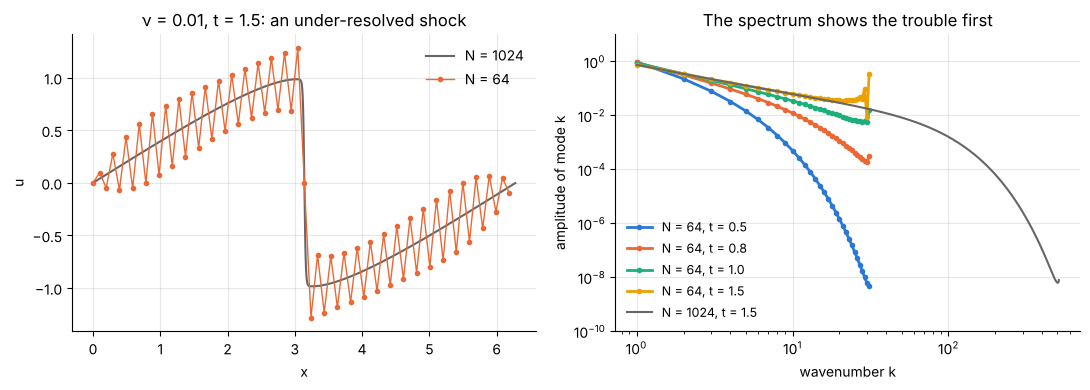

In [11]:
nu = 0.01
def tail(u):
    """Largest of the last four Fourier amplitudes: the part of the spectrum the grid barely holds."""
    return (2 * np.abs(rfft(u)) / len(u))[-4:].max()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
print("N = 64      t    largest error   spectrum tail")
for t in (0.5, 0.8, 1.0, 1.5):
    xg, u = burgers(64, nu, t, 0.005)
    error = np.abs(u - cole_hopf_kernel(xg, t, nu)).max()
    print(f"         {t:4.1f}    {error:9.1e}    {tail(u):9.1e}")
    ax2.loglog(np.arange(1, 32), (2 * np.abs(rfft(u)) / 64)[1:32], "o-", ms=3, label=f"N = 64, t = {t}")
    if t == 1.0:
        u_at_1, error_at_1 = u, error
coarse, error_coarse = u, error

x_fine, fine = burgers(1024, nu, 1.5, 0.00125)
error_fine = np.abs(fine - cole_hopf_kernel(x_fine, 1.5, nu)).max()
print(f"N = 1024   1.5    {error_fine:9.1e}    {tail(fine):9.1e}")
ax2.loglog(np.arange(1, 512), (2 * np.abs(rfft(fine)) / 1024)[1:512], color="0.4", lw=1.5, label="N = 1024, t = 1.5")
ax2.set(xlabel="wavenumber k", ylabel="amplitude of mode k", ylim=(1e-10, 10),
        title="The spectrum shows the trouble first")
ax2.legend(frameon=False, fontsize=9, loc="lower left")

ax1.plot(x_fine, fine, color="0.4", lw=1.5, label="N = 1024")
ax1.plot(xg, coarse, "o-", ms=3, lw=1, color="#eb6834", label="N = 64")
ax1.set(xlabel="x", ylabel="u", title="ν = 0.01, t = 1.5: an under-resolved shock")
ax1.legend(frameon=False, loc="upper right")
fig.tight_layout()

assert coarse.max() > 1.2 and error_coarse > 0.1          # wiggles: the true solution never exceeds 1
print(f"largest u at t = 1 with N = 64: {u_at_1.max():.4f}")
assert u_at_1.max() < 1.001 and error_at_1 > 0.01          # t = 1: looks fine, is already wrong
assert error_fine < 1e-6 and tail(fine) < 1e-8
slope = np.abs(irfft(1j * wavenumbers(1024, 2 * np.pi) * rfft(fine), 1024)).max()
print(f"steepest slope at t = 1.5: {slope:.1f}    estimate U²/(2ν) with U = max u: {fine.max() ** 2 / (2 * nu):.1f}")

The left panel shows the classic symptom: grid-scale oscillations on both sides of the front,
with $u$ overshooting its largest possible value of 1. The table and the right panel show that
the warning came earlier. At $t = 1$ the $N = 64$ profile still looks smooth to the eye and
exceeds 1 only in the fourth decimal place, but its spectrum has stopped decaying at about
$10^{-2}$, and the error is of just that size. **The level at which the Fourier coefficients flatten out is an estimate of
the error**, and it costs one transform to check. In a healthy computation the tail falls to
the accuracy wanted, as the grey curve does.

**How many points?** Near the front the solution is close to the steady shock profile
$u = -U\tanh\!\big(U(x - \pi)/(2\nu)\big)$, whose thickness is about $4\nu/U$ and whose steepest
slope is $U^2/(2\nu)$, the estimate printed above. A Fourier grid has a uniform spacing
$2\pi/N$ and must put several points inside the front wherever it is, so $N$ must grow in
proportion to $1/\nu$: about $5/\nu$ for three or four digits, about $10/\nu$ for the result
above. This is the price of a uniform grid for a thin layer, and for real shocks at high
Reynolds number it rules the approach out (notebook 16 discusses the alternatives).

## 11.6 Kuramoto-Sivashinsky: chaos, and exponential time differencing

**Problem.** The Kuramoto-Sivashinsky (KS) equation

$$u_t = -u\,u_x - u_{xx} - u_{xxxx}$$

models the thickness of a liquid film flowing down a wall and the position of a flame front.
The term $-u_{xx}$ is diffusion with the wrong sign: it pumps energy into long waves. The term
$-u_{xxxx}$ removes it from short waves. A mode $e^{ikx}$ grows at the rate
$\ell(k) = k^2 - k^4$, which is positive for $|k| < 1$ and largest, $\tfrac14$, at
$k = 1/\sqrt2$. The nonlinear term moves energy from the growing modes to the decaying ones.
The result of this three-way exchange, on a domain long enough to hold many unstable modes,
is a pattern of cells that never settles.

**The time-stepping problem.** The symbol reaches $-k_{\max}^4$, so the equation is very stiff,
and some modes grow. The integrating factor of 11.2 still applies, but it has a weakness: it
multiplies the nonlinear term by $e^{\pm\ell t}$, and its error constants are large when
$|\ell|\Delta t$ is large. **Exponential time differencing** (ETD) starts from the same exact
formula and treats it more carefully. Multiply $\hat u_t = \ell\hat u + \hat{\mathcal N}$ by
$e^{-\ell t}$ and integrate over one step:

$$\hat u(t + \Delta t) = e^{\ell\Delta t}\,\hat u(t)
  + \int_0^{\Delta t} e^{\ell(\Delta t - \tau)}\,\hat{\mathcal N}\big(\hat u(t + \tau)\big)\,d\tau .$$

This is exact. The only approximation is to replace $\hat{\mathcal N}$ under the integral by a
polynomial in $\tau$ through a few Runge-Kutta stages, and then to integrate
$e^{\ell(\Delta t - \tau)}\tau^j$ **exactly**. Those integrals are the functions

$$\varphi_1(z) = \frac{e^z - 1}{z},\qquad \varphi_2(z) = \frac{e^z - 1 - z}{z^2},\qquad
\varphi_3(z) = \frac{e^z - 1 - z - z^2/2}{z^3},\qquad z = \ell\,\Delta t .$$

The fourth-order scheme used here is ETDRK4 of Cox and Matthews (*J. Comput. Phys.* 176, 2002),
whose weights are combinations of $\varphi_1, \varphi_2, \varphi_3$.

**A rounding trap.** For small $z$ the formulas subtract nearly equal numbers and then divide by
a power of $z$: at $z = 10^{-6}$ the direct formula for $\varphi_3$ has no correct digits, as
the cell below shows. Kassam and Trefethen (*SIAM J. Sci. Comput.* 26, 2005, p. 1214) proposed
an elegant cure. Each $\varphi_j$ is analytic everywhere, and the value of an analytic function
at a point equals its mean over any circle around that point. So evaluate the formula at
points on a circle of radius 1 around $z$, where nothing cancels, and average. The mean over
equally spaced points on a circle is a trapezoidal rule for a periodic function, which converges
geometrically (notebook 10).

In [12]:
def phi_functions(z, points=32):
    """φ1, φ2, φ3 at the entries of z, as means over circles of radius 1 (no cancellation)."""
    circle = np.exp(2j * np.pi * (np.arange(points) + 0.5) / points)
    zc = np.asarray(z)[..., None] + circle
    ez = np.exp(zc)
    phi = (ez - 1) / zc, (ez - 1 - zc) / zc**2, (ez - 1 - zc - zc**2 / 2) / zc**3
    return [p.mean(axis=-1) for p in phi]

def etdrk4_setup(symbol, dt):
    """Coefficients of the ETDRK4 scheme for u_hat' = symbol * u_hat + nonlinear(u_hat)."""
    p1, p2, p3 = phi_functions(symbol * dt)
    coefficients = [np.exp(symbol * dt), np.exp(symbol * dt / 2), dt / 2 * phi_functions(symbol * dt / 2)[0],
                    dt * (p1 - 3 * p2 + 4 * p3), dt * (2 * p2 - 4 * p3), dt * (4 * p3 - p2)]
    if np.isrealobj(symbol):                                # real symbol: the imaginary parts are rounding errors
        coefficients = [np.real(c) for c in coefficients]
    return coefficients

def etdrk4_step(u_hat, coefficients, nonlinear):
    """One ETDRK4 step: two half-step stages, one full-step stage, then the weighted sum."""
    E, E_half, Q, w1, w23, w4 = coefficients
    n1 = nonlinear(u_hat)
    a = E_half * u_hat + Q * n1
    n2 = nonlinear(a)
    b = E_half * u_hat + Q * n2
    n3 = nonlinear(b)
    c = E_half * a + Q * (2 * n3 - n1)
    n4 = nonlinear(c)
    return E * u_hat + w1 * n1 + w23 * (n2 + n3) + w4 * n4

z = 1e-6
naive = (np.exp(z) - 1 - z - z**2 / 2) / z**3
print(f"φ3(1e-6): direct formula {naive:.6f}   contour mean {phi_functions(z)[2].real:.15f}   exact 1/6 + z/24 = {1 / 6 + z / 24:.15f}")
assert np.allclose(phi_functions(0.0), [1, 1 / 2, 1 / 6], rtol=0, atol=1e-14)
assert np.allclose(phi_functions(np.array([-30.0, 2.0]))[0], (np.exp([-30.0, 2.0]) - 1) / np.array([-30.0, 2.0]), rtol=1e-14)

φ3(1e-6): direct formula -37.816302   contour mean 0.166666708333342   exact 1/6 + z/24 = 0.166666708333333


**Verify the order.** The test is a short run of the KS equation from a smooth state of order
one, against a reference computed with a very small step.

In [13]:
N, L = 256, 32 * np.pi
x = L * np.arange(N) / N
k = wavenumbers(N, L)
ks_symbol = k**2 - k**4
ks_nonlinear = advection_term(k)

def ks_run(u_hat, dt, t_end):
    coefficients = etdrk4_setup(ks_symbol, dt)
    for _ in range(round(t_end / dt)):
        u_hat = etdrk4_step(u_hat, coefficients, ks_nonlinear)
    return u_hat

smooth = rfft(2 * np.cos(2 * np.pi * x / L) + np.sin(6 * np.pi * x / L))
reference = irfft(ks_run(smooth, 1 / 512, 1.0), N)
steps = np.array([1 / 4, 1 / 8, 1 / 16, 1 / 32])
errors = np.array([np.abs(irfft(ks_run(smooth, dt, 1.0), N) - reference).max() for dt in steps])
orders = np.log2(errors[:-1] / errors[1:])
print("dt     ", "  ".join(f"{dt:8.4f}" for dt in steps))
print("error  ", "  ".join(f"{err:8.1e}" for err in errors))
print("observed orders:", np.round(orders, 2))
assert np.all(np.abs(orders - 4) < 0.15)
print(f"largest |symbol| dt at dt = 1/4: {np.abs(ks_symbol).max() / 4:.0f}    (explicit RK4 needs this below 2.8)")

dt        0.2500    0.1250    0.0625    0.0312
error    2.0e-05   1.2e-06   7.7e-08   4.8e-09
observed orders: [3.99 4.01 3.99]
largest |symbol| dt at dt = 1/4: 1008    (explicit RK4 needs this below 2.8)


Fourth order, at steps several hundred times larger than an explicit method could take.

**Verify the linear growth rates.** Start from a perturbation so small ($10^{-10}$ in each of
the first 15 modes) that the nonlinear term is negligible, run to $t = 20$, and measure how
much each mode has grown. The domain of length $32\pi$ holds the wavenumbers $k = n/16$; the
one nearest to $1/\sqrt2$ is $n = 11$.

fastest mode n = 11, k = 0.6875, rate 0.24925    (continuous optimum: k = 0.7071, rate 0.25)


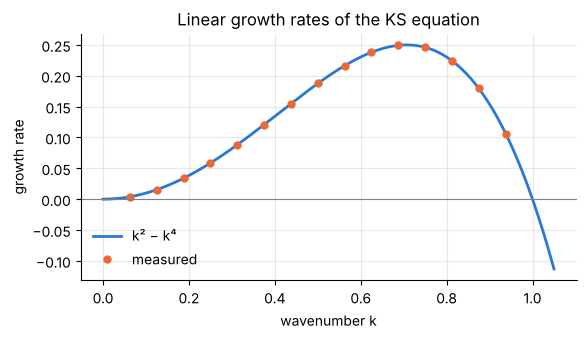

In [14]:
modes = np.arange(1, 16)
tiny = rfft(1e-10 * sum(np.cos(2 * np.pi * n * x / L) for n in modes))
grown = ks_run(tiny, 0.25, 20.0)
rates = np.log(np.abs(grown[modes]) / np.abs(tiny[modes])) / 20.0

fig, ax = plt.subplots(figsize=(6.4, 3.2))
k_fine = np.linspace(0, 1.05, 200)
ax.plot(k_fine, k_fine**2 - k_fine**4, label="k² − k⁴")
ax.plot(k[modes], rates, "o", ms=5, label="measured")
ax.axhline(0, color="0.5", lw=0.8)
ax.set(xlabel="wavenumber k", ylabel="growth rate", title="Linear growth rates of the KS equation")
ax.legend(frameon=False, loc="lower left");

fastest = modes[np.argmax(rates)]
print(f"fastest mode n = {fastest}, k = {k[fastest]:.4f}, rate {rates.max():.5f}    (continuous optimum: k = 0.7071, rate 0.25)")
assert np.abs(rates - ks_symbol[modes]).max() < 1e-9 and fastest == 11 and abs(rates.max() - 0.25) < 1e-3

**The chaotic regime.** Start from a small smooth random perturbation and run to $t = 200$.

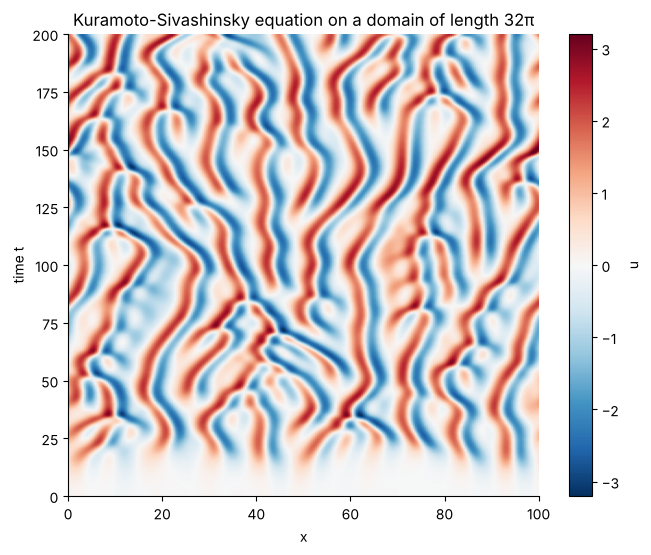

In [15]:
rng = np.random.default_rng(0)
u0 = 0.01 * sum(np.cos(2 * np.pi * n * x / L + phase) for n, phase in zip(range(1, 21), rng.uniform(0, 2 * np.pi, 20)))

dt, t_end, stride = 0.25, 200.0, 2
coefficients = etdrk4_setup(ks_symbol, dt)
u_hat = rfft(u0)
ks_history = [u0]
for step in range(1, round(t_end / dt) + 1):
    u_hat = etdrk4_step(u_hat, coefficients, ks_nonlinear)
    if step % stride == 0:
        ks_history.append(irfft(u_hat, N))
ks_history = np.array(ks_history)
ks_times = dt * stride * np.arange(len(ks_history))

fig, ax = plt.subplots(figsize=(7.6, 6))
mesh = ax.pcolormesh(x, ks_times, ks_history, cmap="RdBu_r", vmin=-3.2, vmax=3.2, shading="gouraud", rasterized=True)
ax.set(xlabel="x", ylabel="time t", title="Kuramoto-Sivashinsky equation on a domain of length 32π")
ax.grid(False)
fig.colorbar(mesh, label="u");

For the first ten time units little can be seen: the perturbation is growing exponentially
from $10^{-2}$ at the rates just measured. By $t \approx 20$ the nonlinear term has saturated
the growth and a pattern of cells has appeared, which drift, merge and split without ever
repeating.

**Verify** what can be verified in a chaotic solution. The spatial mean of $u$ must stay zero,
because every term of the equation is an exact derivative. And the cells should have roughly
the wavelength of the fastest-growing mode, $2\pi\sqrt2 \approx 8.9$, which gives
$32\pi/(2\pi\sqrt2) \approx 11.3$ cells across the domain.

In [16]:
mean_drift = np.abs(ks_history.mean(axis=1)).max()
developed = ks_history[ks_times >= 60]
cells = ((developed * np.roll(developed, 1, axis=1)) < 0).sum(axis=1).mean() / 2      # two sign changes per cell
print(f"largest |mean of u| = {mean_drift:.1e}")
print(f"average number of cells for t > 60: {cells:.1f}    estimate from the fastest-growing mode: {L / (2 * np.pi * np.sqrt(2)):.1f}")
print(f"largest |u| = {np.abs(developed).max():.2f}, root mean square = {developed.std():.2f}")
assert mean_drift < 1e-12 and abs(cells / 11.3 - 1) < 0.15 and np.abs(developed).max() < 5

# the order test of the time stepping again, now from the chaotic state at t = 200 and down to smaller steps
fine_steps = 1 / 2.0 ** np.arange(2, 10)                                # 1/4, 1/8, ..., 1/512
reference = irfft(ks_run(u_hat, 1 / 4096, 1.0), N)
errors = np.array([np.abs(irfft(ks_run(u_hat, step, 1.0), N) - reference).max() for step in fine_steps])
chaotic_orders = np.log2(errors[:-1] / errors[1:])
print("chaotic state, dt from 1/4 to 1/512")
print("error  ", "  ".join(f"{err:8.1e}" for err in errors))
print("observed orders:", np.round(chaotic_orders, 2))
assert np.all((chaotic_orders[:3] > 2.8) & (chaotic_orders[:3] < 3.4))  # close to three at practical steps
assert np.all(np.diff(chaotic_orders[2:]) > 0) and chaotic_orders[-1] > 3.7   # and back towards four as dt → 0

largest |mean of u| = 4.2e-17
average number of cells for t > 60: 11.3    estimate from the fastest-growing mode: 11.3
largest |u| = 3.42, root mean square = 1.30


chaotic state, dt from 1/4 to 1/512
error    9.0e-04   1.1e-04   1.3e-05   1.4e-06   1.3e-07   1.0e-08   7.6e-10   5.2e-11
observed orders: [3.1  3.05 3.17 3.47 3.65 3.75 3.87]


**What it means.** The individual cells are unpredictable: a change in the tenth digit of the
initial condition grows exponentially and eventually gives a completely different picture.
The statistics are not:
the cell size, the amplitude and the spectrum are reproducible, and those are the quantities
an engineer can ask of a chaotic system, whether it is a wavy film in a condenser or a
turbulent flow. Linear theory supplied the cell size; the amplitude is set by the nonlinear
term and has to be computed.

A caution about the order of accuracy, from the last lines of output. The fourth-order test
earlier used a smooth state. On the developed chaotic state, with $\Delta t$ in the practical
range where $|\ell|\Delta t$ is large for many modes, the same test gives an observed order
close to three. This **order reduction** is a known property of exponential integrators for
stiff problems. It belongs to that range and not to the limit $\Delta t \to 0$: as the step
is reduced further the observed order climbs back towards four, to 3.9 at the smallest steps
tried. The errors remain small, about $10^{-3}$ at $\Delta t = 1/4$ over one time unit, but a
convergence test on a smooth solution can flatter a stiff solver.

## Summary

- On a domain of period $L$ the wavenumbers are $2\pi n/L$. For real data use `rfft`, which
  also keeps rounding errors from creating an imaginary part.
- A constant-coefficient linear term is a multiplication by its symbol $\ell(k)$ in Fourier
  space and can be integrated **exactly**: by an integrating factor, or better by exponential
  time differencing. Only the nonlinear term then limits the stable time step.
- KdV solitons survive collisions with a phase shift; the computation reproduces the exact
  shifts, speeds and conserved quantities.
- A viscous shock of thickness about $4\nu/U$ needs $N$ of order $1/\nu$ on a uniform grid.
  A Fourier spectrum that stops decaying is the first sign of under-resolution, and its level
  estimates the error.
- For chaotic solutions verify the scheme (order, invariants, linear growth rates) and then
  trust statistics, not individual trajectories.

## Exercises

1. **Soliton fission.** Solve the KdV equation of 11.3 on the same grid ($N = 256$, $L = 30$)
   from the initial condition $u(x, 0) = 36\,\operatorname{sech}^2(x + 8)$, which is *not* a
   single soliton (a soliton of height 36 would have $\operatorname{sech}^2(\sqrt3\,(x+8))$).
   Run to $t = 1$ with $\Delta t = 10^{-4}$ and use `peaks` to find how many solitons emerge
   and their heights. Theory predicts exactly two, of heights 48 and 12. Check also that each
   travels at one third of its height.
2. **Phase shifts for other speeds.** Repeat the collision of 11.4 with $c_1 = 9$ and $c_2 = 1$
   on a domain of length $L = 60$ with $N = 512$, starting the solitons at $x_1 = -20$ and
   $x_2 = -8$ and running to $t = 4$ with $\Delta t = 2\times10^{-4}$. Measure both phase shifts
   and compare them with the formula of 11.4.
3. **A soliton of the nonlinear Schrödinger equation.** The equation
   $i\psi_t + \tfrac12\psi_{xx} + |\psi|^2\psi = 0$ for a complex field $\psi$ has the solution
   $\psi = a\,\operatorname{sech}\!\big(a(x - Vt)\big)\exp\!\big(i\,[Vx + \tfrac12(a^2 - V^2)t]\big)$.
   Write an integrating-factor RK4 code for it (the data are complex, so use `fft`, `ifft` and
   `np.fft.fftfreq`; the symbol is $-ik^2/2$ and the nonlinear term is $i|\psi|^2\psi$). With
   $a = 2$, $V = 1$, $L = 40$, $N = 256$ and $\Delta t = 10^{-3}$, verify the solution at
   $t = 4$ to $10^{-6}$ and check that $\int|\psi|^2dx = 2a$ is conserved.
4. **Shock thickness.** For the Burgers problem of 11.5 at $t = 2$, compute the steepest slope
   $\max|u_x|$ for $\nu = 0.1$, 0.05 and 0.025, each with a grid fine enough that the spectrum
   tail is below $10^{-10}$ (state the $N$ you needed). Compare each with the steady-shock
   estimate $U^2/(2\nu)$, where $U$ is the largest value of $u$ at that time. Show that the
   ratio of successive slopes approaches 2 as $\nu$ is halved, and that the estimate improves
   as $\nu$ falls.
5. **The onset of the Kuramoto-Sivashinsky instability.** On a domain of length $L$ the
   longest wave has $k = 2\pi/L$, so the flat state $u = 0$ is stable when $L < 2\pi$. With
   $N = 64$, $\Delta t = 0.1$ and the initial condition $u = 0.01\cos(2\pi x/L)$, run the KS
   code to $t = 100$ for $L = 6$ and for $L = 10$. For $L = 6$, measure the decay rate of the
   amplitude and compare it with $k^2 - k^4$. For $L = 10$, show that the solution settles to a
   steady cellular state, and report its largest value of $|u|$ at $t = 100$ and how much that
   value changes between $t = 90$ and $t = 100$.